# Patterns in STEAM game data (working title)

Blurb to be inserted, talk about:
We are looking into steam data (explain it and its source) to look for indicators of success in a developer's career, and trying to tie it with factors such as career span and more stuff


The notebook is divided into 8 sections
- Data Understanding
- Data Quality
- Preprocessing
- Exploratory Data Analysis
- Pattern Discovery
- Evaluation
- Decision Sensitivity
- Interpretation

## A. Data Understanding

In this section we will:
- Import the data
- Look at its shape and baseline statistics
- Probably more stuff

In [2]:
# Necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Loading our data

Let us first import our data, originally obtained from [Kaggle](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset/data). The csv file is already located under the same directory.

Note: when simply running `pd.read_csv("games.csv")`, two columns, `Discount` and `DLC count`, end up merging, due to a missing comma between the two of them. A solution found is to explicitely passing a list of column names to be loaded


In [3]:
columns = ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']

df = pd.read_csv("games.csv",names=columns, header=0)

### Looking at the shape and attributes of our data

With our data correclty loaded, let us look at its initial basic attributes

In [4]:
df.shape

(125855, 40)

In [5]:
df.columns

Index(['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU',
       'Required age', 'Price', 'Discount', 'DLC count', 'About the game',
       'Supported languages', 'Full audio languages', 'Reviews',
       'Header image', 'Website', 'Support url', 'Support email', 'Windows',
       'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score',
       'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations',
       'Notes', 'Average playtime forever', 'Average playtime two weeks',
       'Median playtime forever', 'Median playtime two weeks', 'Developers',
       'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies'],
      dtype='str')

We have a dataframe of steam games, with 125855 entries, each representing a distinct game available on the Steam store, and 40 attributes, describing each entry, such as its name, price, and more

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  str    
 2   Release date                125855 non-null  str    
 3   Estimated owners            125855 non-null  str    
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  str    
 10  Supported languages         125855 non-null  str    
 11  Full audio languages        125855 non-null  str    
 12  Reviews                     12181 non-null   str    
 13  Header image             

In [7]:
df.describe()

,AppID,Peak CCU,Required age,Price,Discount,DLC count,Metacritic score,User score,Positive,Negative,Score rank,Achievements,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Movies
count,1.258550e+05,1.258550e+05,125855.000000,125855.000000,125855.000000,125855.000000,125855.000000,125855.000000,1.258550e+05,1.258550e+05,40.000000,125855.000000,1.258550e+05,1.258550e+05,125855.000000,1.258550e+05,125855.000000,0.0
mean,2.032627e+06,5.318720e+01,0.165365,4.811174,17.896826,0.535434,2.500083,0.023916,1.018182e+03,1.648786e+02,99.175000,17.922220,9.380399e+02,2.027568e+02,13.507711,1.691803e+02,14.419125,NaN
std,1.117434e+06,3.681083e+03,1.642666,12.489329,28.628518,14.328417,13.492922,1.376811,2.772782e+04,5.305001e+03,0.675107,139.696425,2.159585e+04,1.107222e+04,266.925759,1.105725e+04,290.747134,NaN
min,1.000000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,98.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
25%,1.083495e+06,0.000000e+00,0.000000,0.590000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,99.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
50%,1.949010e+06,0.000000e+00,0.000000,2.390000,0.000000,0.000000,0.000000,0.000000,4.000000e+00,1.000000e+00,99.000000,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
75%,2.938410e+06,0.000000e+00,0.000000,5.545000,37.000000,0.000000,0.000000,0.000000,3.500000e+01,1.000000e+01,100.000000,19.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
max,4.437540e+06,1.013936e+06,21.000000,999.980000,100.000000,3703.000000,97.000000,100.000000,7.642084e+06,1.173003e+06,100.000000,9821.000000,4.830455e+06,3.429544e+06,20088.000000,3.429544e+06,20088.000000,NaN


In [5]:
df.dtypes

AppID                           int64
Name                              str
Release date                      str
Estimated owners                  str
Peak CCU                        int64
Required age                    int64
Price                         float64
Discount                        int64
DLC count                       int64
About the game                    str
Supported languages               str
Full audio languages              str
Reviews                           str
Header image                      str
Website                           str
Support url                       str
Support email                     str
Windows                          bool
Mac                              bool
Linux                            bool
Metacritic score                int64
Metacritic url                    str
User score                      int64
Positive                        int64
Negative                        int64
Score rank                    float64
Achievements

| Attribute  | Statistical Data Type |  What it describes  |
|-------|-----|-------|
| AppID | Categorical, identifier  | Unique identifier given to each game by Steam |
| Name | Categorical  | Name of the game |
| Release date | Ordinal  | Date when the game was released |
| Estimated owners | Ratio  | range scale formatted as a string of estimated count of owners for the game |
| Peak CCU | Ratio  | count of highest concurrent players playing the game at a given time |
| Required age | Ratio  | minimum age required to play the game in years |
| Price | Continuous  | cost in USD of the game on the Steam store |


- Discount - int64, discount offered at the time of scraping on the Steam store (percentage)
- DLC count - int64, count of how many DLC (downloadable content) available for the game
- About the game - str, short blurb describing the game
- Supported languages - str, list of languages supported for the game
- Full audio languages - str, list of languages supported for the game for in game audio
- Reviews - str, user reviews
- Header image - str, link to an image displayed at the Steam store for the game
- Website - str, link to the website for the game
- Support url - str, link to the support page for the game
- Support email - str, link to the support email for the game
- Windows - bool, whether there is Windows OS support for the game 
- Mac - bool, whether there is Mac OS support for the game
- Linux - bool, whether there is Linux OS support for the game
- Metacritic score - int64, score metric by critics to the game, measured on a normalized 0 to 100 rating scale / points (critic review aggregate).
- Metacritic url - str, link to the critics
- User score - int64, score given by users, typically measured on a 0 to 100 scale or 0 to 10 scale (depending on whether it mirrors Metacritic's 0–100 scale or 0–10 point user rating
- Positive - int64, count of how many “positive” votes were given to the game
- Negative -  int64, count of how many “negative” votes were given to the game
- Score rank - float64, internal ranking based on the ratio between positive and negative reviews, measured as a percentile rank or ranking index representing review sentiment ranking relative to other titles 
- Achievements - int64, the total count of steam achievements available to unlock the game
- Recommendations - int64, the count of positive recommendations submitted by users
- Notes - str, notes and warnings regarding the game
- Average playtime forever - int64, the mean total playtime across all owners since the game’s release, measured in minutes
- Average playtime two weeks - int64, the mean playtime per player in the 2 weeks preceding scraping, measured in minutes
- Median playtime forever - int64, median total playtime recorded across all owners since release, measured in minutes
- Median playtime two weeks - int64, median playtime recorded per player during the previous two-week period, measured in minutes
- Developers - str, name of the developers
- Publishers - str, name of the publishers
- Categories - str, technical and platform capabilities provided by steam                        
- Genres - str, high-level store genres assigned by the publisher/developer
- Tags - str, community-applied descriptive tags reflecting gameplay themes sub-genres, and tone
- Screenshots - str, link to the screenshots available at the game page on Steam Store    
- Movies - str, link to the movies available at the game page on Steam Store

### Visualizing our data

Let us look at a pattern of interest: the engagement developer receive according to the number of games they have released

([<matplotlib.axis.XTick at 0x7fa82066f4d0>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12'),
  Text(13, 0, '13'),
  Text(14, 0, '14'),
  Text(15, 0, '15'),
  Text(16, 0, '16'),
  Text(17, 0, '17'),
  Text(18, 0, '18'),
  Text(19, 0, '19'),
  Text(20, 0, '20'),
  Text(21, 0, '21'),
  Text(22, 0, '22'),
  Text(23, 0, '23'),
  Text(24, 0, '24'),
  Text(25, 0, '25'),
  Text(26, 0, '26'),
  Text(27, 0, '27'),
  Text(28, 0, '28'),
  Text(29, 0, '29'),
  Text(30, 0, '30'),
  Text(31, 0, '31'),
  Text(32, 0, '32'),
  Text(33, 0, '33'),
  Text(34, 0, '34'),
  Text(35, 0, '35'),
  Text(36, 0, '36'),
  Text(37, 0, '37'),
  Text(38, 0, '38'),
  Text(39, 0, '39'),
  Text(40, 0, '40'),
  Text(41, 0, '41'),
  Text(42, 0, '42'),
  Text(43, 0, '43'),
  Text(44, 0, '44'),
  Text(45, 0, '45'),
  Text(46, 0, '46'),
  Text(

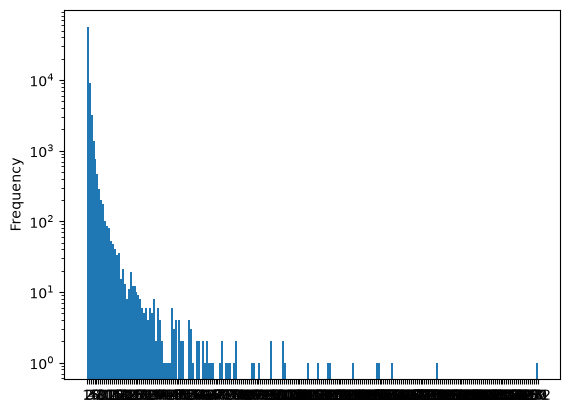

In [ ]:

result = df.groupby("Developers").agg(
    positive=("Positive", "sum"),
    count=("Developers", "size")
)
maxX = round(result["count"].max())
result["count"].plot.hist(bins=range(1,maxX+1))
plt.yscale("log")
plt.xticks(range(1,maxX+1))

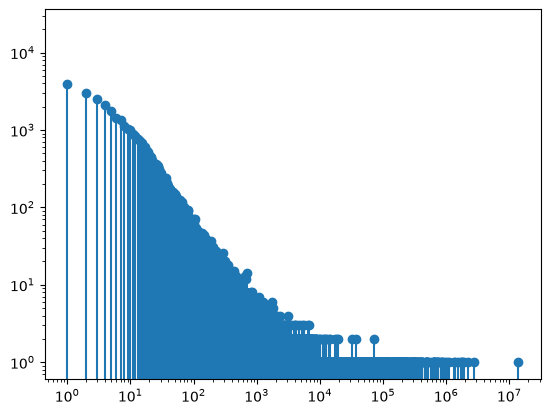

In [7]:
freq = result['positive'].value_counts().sort_index()

plt.stem(freq.index, freq.values)
plt.yscale("log")
plt.xscale("log")

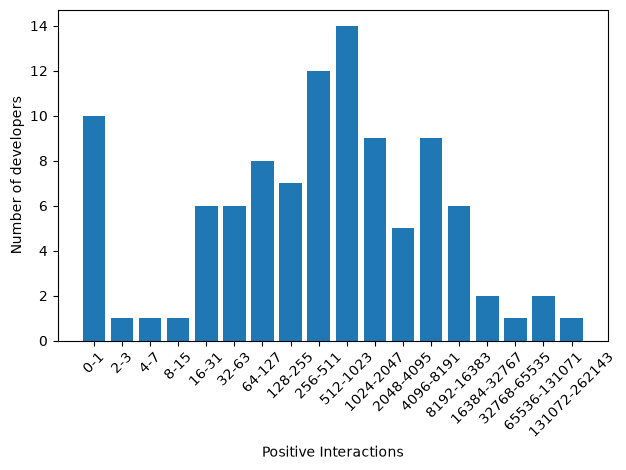

In [14]:
dev_game_four = result[result["count"] == 10]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_four["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_four["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
dev_game_four.shape

(101, 2)

## B. Data Quality

### Duplicates

In [11]:
duplicates = df[df.duplicated() == True]
duplicates.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies


### Missing values

Let us check for how many missing entries in our dataset

In [8]:
df.isnull().sum()

AppID                              0
Name                               1
Release date                       0
Estimated owners                   0
Peak CCU                           0
Required age                       0
Price                              0
Discount                           0
DLC count                          0
About the game                  8462
Supported languages                0
Full audio languages               0
Reviews                       113674
Header image                      81
Website                        75335
Support url                    70560
Support email                  22630
Windows                            0
Mac                                0
Linux                              0
Metacritic score                   0
Metacritic url                121597
User score                         0
Positive                           0
Negative                           0
Score rank                    125815
Achievements                       0
R

## C. Preprocessing

In [9]:
df.columns

Index(['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU',
       'Required age', 'Price', 'Discount', 'DLC count', 'About the game',
       'Supported languages', 'Full audio languages', 'Reviews',
       'Header image', 'Website', 'Support url', 'Support email', 'Windows',
       'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score',
       'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations',
       'Notes', 'Average playtime forever', 'Average playtime two weeks',
       'Median playtime forever', 'Median playtime two weeks', 'Developers',
       'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies'],
      dtype='str')

In [18]:
df.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


We are mainly interested in using  the following columns:
- AppID, Name, Release data, 
So - can be dropped for our purposes:
- Discount, , Full audio languages, Reviews, Peak CCU, 

In [15]:
df.shape

(125855, 40)

In [17]:
df['DLC count'].sum()

np.int64(67387)

In [16]:
new_df = df[df['DLC count'] >=1]
new_df.shape

(18032, 40)

In [22]:
new_df = df[(df['Windows'] == False)]
new_new_df = new_df[(new_df['Linux'] == True)]
new_new_df.shape

(14, 40)

In [23]:
new_new_df

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
3731,1238470,Come on-be with you,"Feb 13, 2020",0 - 20000,0,0,0.99,0,0,NaN,...,0,0,0,yu,yun,"Single-player,Family Sharing","Action,Casual,Indie,Simulation,Sports,Strategy","Sports,Casual,Indie,2D Platformer,2D,Singlepla...",NaN,NaN
6290,3946320,PSStream,"Nov 2, 2025",0 - 0,0,0,4.99,0,0,"PSStream offers high-quality, low-latency PS c...",...,0,0,0,Forward Technologies,Forward Technologies,"Full controller support,Steam Cloud","Utilities,Video Production",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
23737,364380,CINEVEO - VR Cinema,"Apr 24, 2015",20000 - 50000,0,0,29.99,0,0,----------------------------------------------...,...,0,193,0,Mindprobe Labs,Mindprobe Labs,"Single-player,Multi-player,Cross-Platform Mult...",Simulation,"Simulation,VR,First-Person,Multiplayer,Cinemat...",https://shared.akamai.steamstatic.com/store_it...,NaN
29709,3994710,Mr Toffee's Slow-Thermo Sudoku Puzzles,"Oct 19, 2025",0 - 20000,0,0,5.99,0,0,Sudoku with an artsy twist. Full-colour hand-...,...,0,0,0,Tom Fry,Tom Fry,"Single-player,Full controller support,Family S...","Casual,Indie",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
40021,2404100,女王,"Jun 11, 2024",0 - 0,0,0,0.00,0,0,"In this game world, you can obtain different q...",...,0,0,0,做世界,做世界,"Multi-player,Co-op,Online Co-op,Partial Contro...","Action,Adventure,Casual,Massively Multiplayer,...",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
41190,2141560,Star Rising,"Jun 30, 2025",0 - 20000,0,0,34.99,0,0,"Star Rising is a dungeon crawling, spatial-dec...",...,0,0,0,gopokyo Inc.,gopokyo Inc.,"Single-player,Family Sharing","Indie,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
43259,3234590,Scroll Wheel Adjuster,"Oct 17, 2024",0 - 20000,0,0,0.99,0,0,This application allows you to adjust the mous...,...,0,0,0,RGByte Software,RGByte Software,NaN,Utilities,"Utilities,Software",https://shared.akamai.steamstatic.com/store_it...,NaN
44299,1178330,es,"Nov 4, 2019",0 - 20000,0,0,0.00,0,0,NaN,...,0,0,0,Fly,g,"Single-player,Family Sharing","Action,Adventure,Casual,Indie,Simulation,Strategy",NaN,NaN,NaN
82463,1157360,Lif,"Sep 27, 2019",0 - 20000,0,0,0.00,0,0,NaN,...,0,0,0,MZ,MZ,"Single-player,Family Sharing","Action,Indie,RPG,Sports","Action,Sports,Indie,First-Person,Singleplayer,...",NaN,NaN
88247,594550,Arma: Cold War Assault Mac/Linux,"Mar 14, 2017",20000 - 50000,0,17,0.99,0,0,Bohemia Interactive's debut game published by ...,...,0,255,0,Bohemia Interactive,Bohemia Interactive,"Single-player,Family Sharing","Action,Simulation,Strategy","Action,Simulation,Strategy,Violent,Gore,Cold W...",https://shared.akamai.steamstatic.com/store_it...,NaN


In [19]:
df.columns

Index(['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU',
       'Required age', 'Price', 'Discount', 'DLC count', 'About the game',
       'Supported languages', 'Full audio languages', 'Reviews',
       'Header image', 'Website', 'Support url', 'Support email', 'Windows',
       'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score',
       'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations',
       'Notes', 'Average playtime forever', 'Average playtime two weeks',
       'Median playtime forever', 'Median playtime two weeks', 'Developers',
       'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies'],
      dtype='str')

To keep:

- AppID
- Name
- Release
- Price: may be used to validate our findings and groups
- Count DLC as different games?
    - Every game with at least 1 DLC counts as 2
        - We will justify this data transformation
- Positive
- Negative
- Developers
- Genres

If we look ate front page effort
- About the game
- Screenshots
- Movies

For sure developer success based on number of games analysis
- Does the removal of adult games weaken our hypothesis?
- What type of growth can be found? Linear, or a different kind?

cdeveloper success based on release interval

Correlation of sale games to positive and negative counts

Relationship between adult games
- if we remove all adult games, what happens to our data?

Not used at all:
- Peak CCU - favors certain styles of games
- Required age
- Games with the `adult content` tag
- Discount
- Supported languages
- Full audio languages
- Reviews
- Header image
- Website
Support website
- Support url
- Windows
- Mac
- Linux
- Metacritic score
- Metacritic Url
- User score
- Score rank
- Achievements
- Recommendations
- Notes
- Average playtime forever', 'Average playtime two weeks',
       'Median playtime forever', 'Median playtime two weeks'
- Publishers
- Categories
- Tags

## D. Exploratory Data Analysis

## E. Pattern Discovery

## F. Evaluation

<a id='section1></a>

## G. Decision Sesnsitivity Analysis

## H. Interpretation